# Bounce white noise per DZ term from B−A pairs (v1)

**Author:** Aaron Roodman (with Claude)  
**Date Created:** 2026-11-02  
**Last Modified:** 2026-11-02  
**Status:** In Progress  
**Keywords:** bounce, white noise, DZ, B−A pairs, BLOCK-T720  

## Description

The per-visit white-noise floor of each of the 126 DZ_kj terms (k = 1–6, the 21
pupil j), from the B−A pairs of the BLOCK-T720 elevation sweep.

Each pair gives d = DZ_B − DZ_A, about 2.8 min apart. Subtracting the (night, leg)
median of d removes the real elevation step. What remains is the visit-to-visit
noise of two visits, so the per-visit scatter is sqrt(D/2), with D the mean square
of the centred d.

Two estimates per term:

- RMS: sqrt(sum d² / (2 (N − G))), N = number of pairs, G = number of (night, leg)
  groups, which each lose one degree of freedom to the median.
- nMAD: 1.4826 median(|d|) / sqrt(2), robust to the few large pairs.

Both include the red drift over 2.8 min, so they are upper limits on the white floor.

**Output:** `bounce_white_noise_pairs.pdf` (one histogram per DZ term, then the
summary) and `bounce_white_noise_pairs.csv`.

**Based on:** `bounce_aba_optical_state_v1`, whose shared-ALPHA variogram puts the
DZ(1,4) floor near zero; the expected atmospheric Z4 floor is about 0.040 µm per visit.

## Change Log

| Date | Author | Description |
|------|--------|-------------|
| 2026-11-02 | Aaron Roodman | Initial version |

## Table of Contents

1. [Parameters](#params)
2. [Setup & Imports](#setup)
3. [Data Access](#data)
4. [B−A pairs](#pairs)
5. [Histograms](#hist)
6. [Summary](#summary)
7. [Save](#save)

<a id='params'></a>
## Parameters

In [1]:
DAY_OBS = [20260418, 20260419, 20260513, 20260709, 20260711, 20260713]
BOUNCE = 'T720_elevation'          # bounce name from analysis_config.yaml

PARAM_SET = 'danish_1_3'
MI_NAME = 'pathA_50_50_i_rbr_5rot'
MIW_VARIANT = 'd13-A_50_50_i_rbr_5rot'
MIW_BUILD = '20261028b'
MIN_DETECTORS = 160                # the bounce run's --min-detectors

J_PER_PAGE = 4                     # histogram pages: k = 1..6 across, this many j down
N_BINS = 20
FLOOR_Z4_UM = 0.040                # expected atmospheric Z4 floor per visit, um
SAVE = True

from rubinwork.common import study_run
run = study_run('aos/bounce', 'white_noise_pairs')

<a id='setup'></a>
## Setup & Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

from rubinwork.bounce import legs as bl
from rubinwork.bounce import analysis as ba
from rubinwork.common.utils import repo_root
from rubinwork.products import catalog
from lsst.ts.intrinsic.wavefront.ofc_svd import build_ofc_svd, project_dz_table

pd.set_option('display.width', 200)

<a id='data'></a>
## Data Access

The fit table goes through the same bad-fit drop and quality cut as the bounce run.
The DZ come from the same projection (`project_dz_table`) the A–B–A notebook uses.

In [3]:
cfg = bl.resolve_config(PARAM_SET, MI_NAME,
                        analysis_config=repo_root() / 'aos' / 'analysis_config.yaml')
prefix = cfg['fit_prefix']
b = next(x for x in cfg['bounces'] if x['name'] == BOUNCE)
ft = ba.load_fit_table(catalog.path('miw', MIW_VARIANT, build=MIW_BUILD) / 'fits.parquet',
                       cfg, min_detectors=MIN_DETECTORS)
iZs = list(cfg['pupil_j_range']); kr = cfg['focal_k_range']; ks = list(range(min(kr), max(kr) + 1))
svd = build_ofc_svd(iZs, int(min(kr)), int(max(kr)), int(cfg['rbr_n_keep']), n_dof=cfg['n_dof'],
                    ofc_normalization_yaml=cfg['ofc_normalization_yaml'])
_, _, _, W = project_dz_table(ft, prefix, svd)      # (visit, kj) um of wavefront
KJ = list(svd.kj_grid); NT = len(KJ)
print(f'{len(ft)} visits, {NT} DZ terms')

  dropping 11 bad-flagged visits (z1toz6_bad_fit)


        Use pytest instead. [astropy.tests.runner]
        Use pytest instead.


        Use pytest instead. [astropy.utils.decorators]
        Use pytest instead.


INFO:lsst.ts.utils.tai:Update leap second table


INFO:lsst.ts.utils.tai:current_tai uses the system TAI clock


  quality cut (min_detectors=160): 1575/2012 visits kept


1575 visits, 126 DZ terms


<a id='pairs'></a>
## B−A pairs

The pairs are those of the bounce run (`form_pairs`): each visit is paired once
with the next visit of the other setting.

In [4]:
dobs = np.asarray(ft['day_obs']).astype(int)
seq = np.asarray(ft['seq_num']).astype(int)
mjd = np.asarray(ft['mjd'], float)
rows = []
for d in DAY_OBS:
    rb = bl.run_bounce(ft, b, prefix, [1], [4], day_obs=d)
    for lab, cb in rb['comparisons'].items():
        for r, c in cb['pairs']:
            rows.append({'night': d, 'leg': lab, 'row_A': r, 'row_B': c, 'seq_A': seq[r],
                         'seq_B': seq[c], 'lag_min': (mjd[c] - mjd[r]) * 1440.0})
pairs = pd.DataFrame(rows)
dp = W[pairs.row_B] - W[pairs.row_A]                 # (pair, kj) um
step = np.zeros_like(dp); dc = np.zeros_like(dp)
groups = pairs.groupby(['night', 'leg']).indices
for _, ix in groups.items():
    step[ix] = np.median(dp[ix], 0)
    dc[ix] = dp[ix] - step[ix]
N, G = len(pairs), len(groups)
print(f'{N} pairs in {G} (night, leg) groups; lag {pairs.lag_min.min():.1f}-{pairs.lag_min.max():.1f} min')
pairs.groupby(['night', 'leg']).agg(n=('seq_A', 'size'), lag_med_min=('lag_min', 'median'))

45 pairs in 7 (night, leg) groups; lag 2.6-3.1 min


n  lag_med_min
night    leg                     
20260418 Elev=40   6     2.784815
20260419 Elev=40  10     2.791447
20260513 Elev=40   8     2.830489
20260709 Elev=60   4     2.684719
20260711 Elev=50   6     2.738022
20260713 Elev=30   5     2.883628
         Elev=75   6     2.613304

In [5]:
rms_w = np.sqrt((dc ** 2).sum(0) / (2 * (N - G)))
nmad_w = 1.4826 * np.median(np.abs(dc), 0) / np.sqrt(2)
# chi2 error of an RMS: sigma / sqrt(2 dof)
rms_w_err = rms_w / np.sqrt(2 * (N - G))
tab = pd.DataFrame({'k': [k for k, _ in KJ], 'j': [j for _, j in KJ],
                    'mean_d_um': dc.mean(0), 'median_d_um': np.median(dc, 0),
                    'sigma_rms_um': rms_w, 'sigma_rms_err_um': rms_w_err, 'sigma_nmad_um': nmad_w,
                    'max_abs_d_um': np.abs(dc).max(0)})
i14 = KJ.index((1, 4))
print(f'DZ(1,4): sigma_rms = {rms_w[i14]:.4f} +- {rms_w_err[i14]:.4f} um, sigma_nmad = {nmad_w[i14]:.4f} um '
      f'per visit (expected floor {FLOOR_Z4_UM:.3f} um)')
tab.sort_values('sigma_rms_um', ascending=False).head(10)

DZ(1,4): sigma_rms = 0.0437 +- 0.0050 um, sigma_nmad = 0.0215 um per visit (expected floor 0.040 um)


,k,j,mean_d_um,median_d_um,sigma_rms_um,sigma_rms_err_um,sigma_nmad_um,max_abs_d_um
1,1,5,-0.007041,0.0,0.128714,0.014765,0.065725,0.688237
2,1,6,-0.009824,0.0,0.076695,0.008797,0.046282,0.343628
5,1,9,-0.000190,0.0,0.054920,0.006300,0.025556,0.290052
6,1,10,0.000932,0.0,0.044294,0.005081,0.025864,0.222307
0,1,4,-0.008868,0.0,0.043702,0.005013,0.021516,0.192100
4,1,8,0.000064,0.0,0.034281,0.003932,0.016086,0.168722
11,1,15,-0.000342,0.0,0.033490,0.003842,0.009596,0.176665
3,1,7,-0.000769,0.0,0.028865,0.003311,0.024047,0.105365
44,3,6,0.003249,0.0,0.023660,0.002714,0.014957,0.142343
10,1,14,0.000488,0.0,0.018964,0.002175,0.012231,0.100835


<a id='hist'></a>
## Histograms

One panel per DZ_kj: the N centred d, with the mean (red) and median (blue). The
median of the centred d is near zero by construction. The title gives both
per-visit estimates.

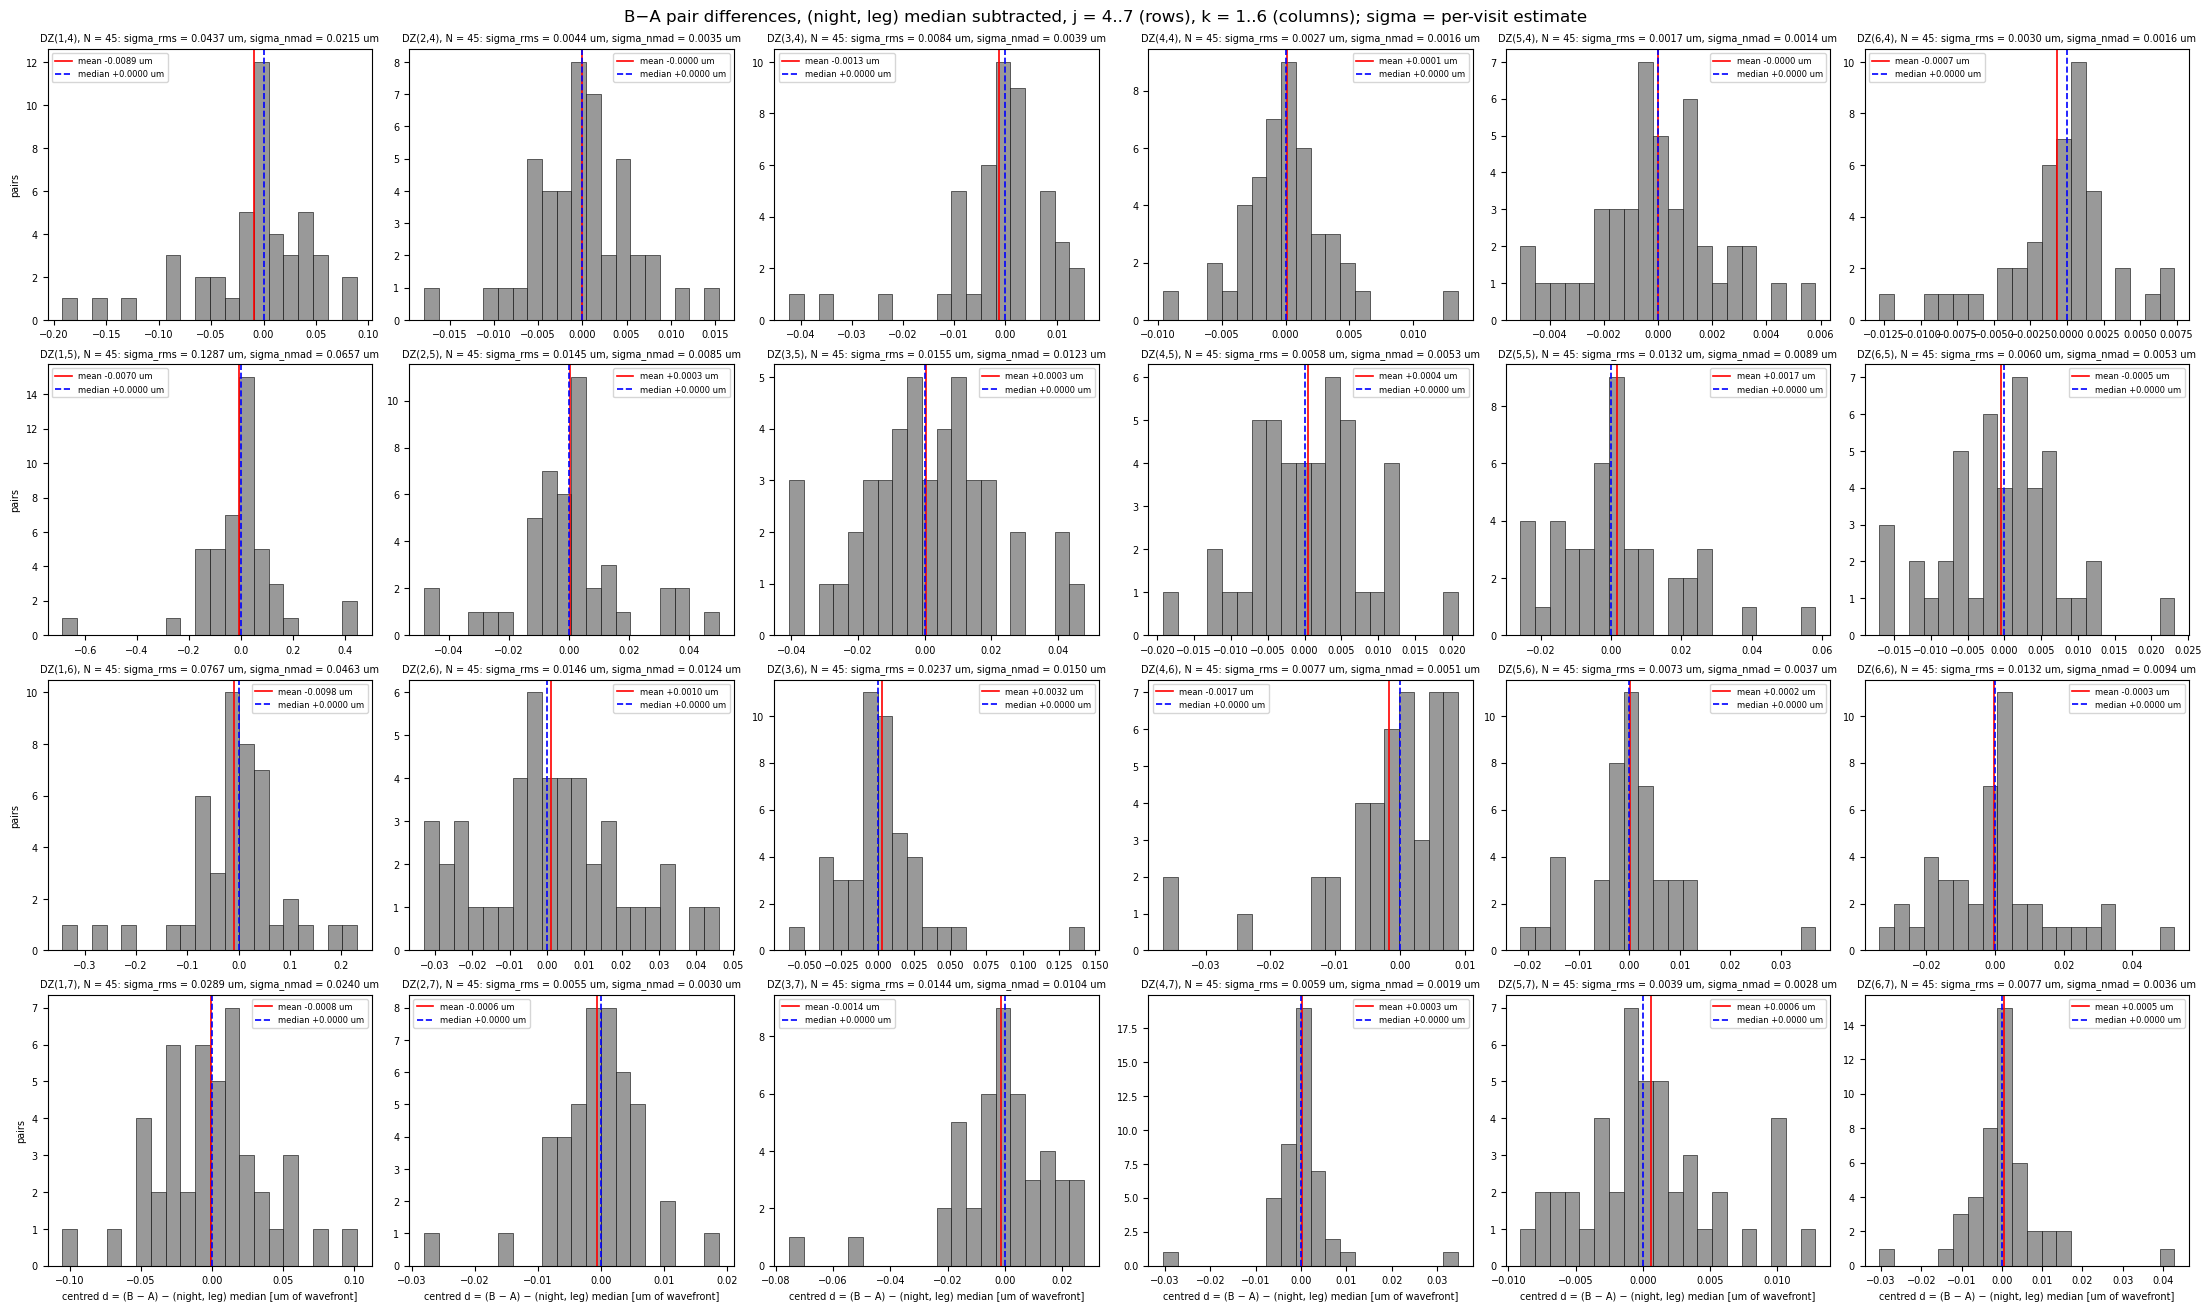

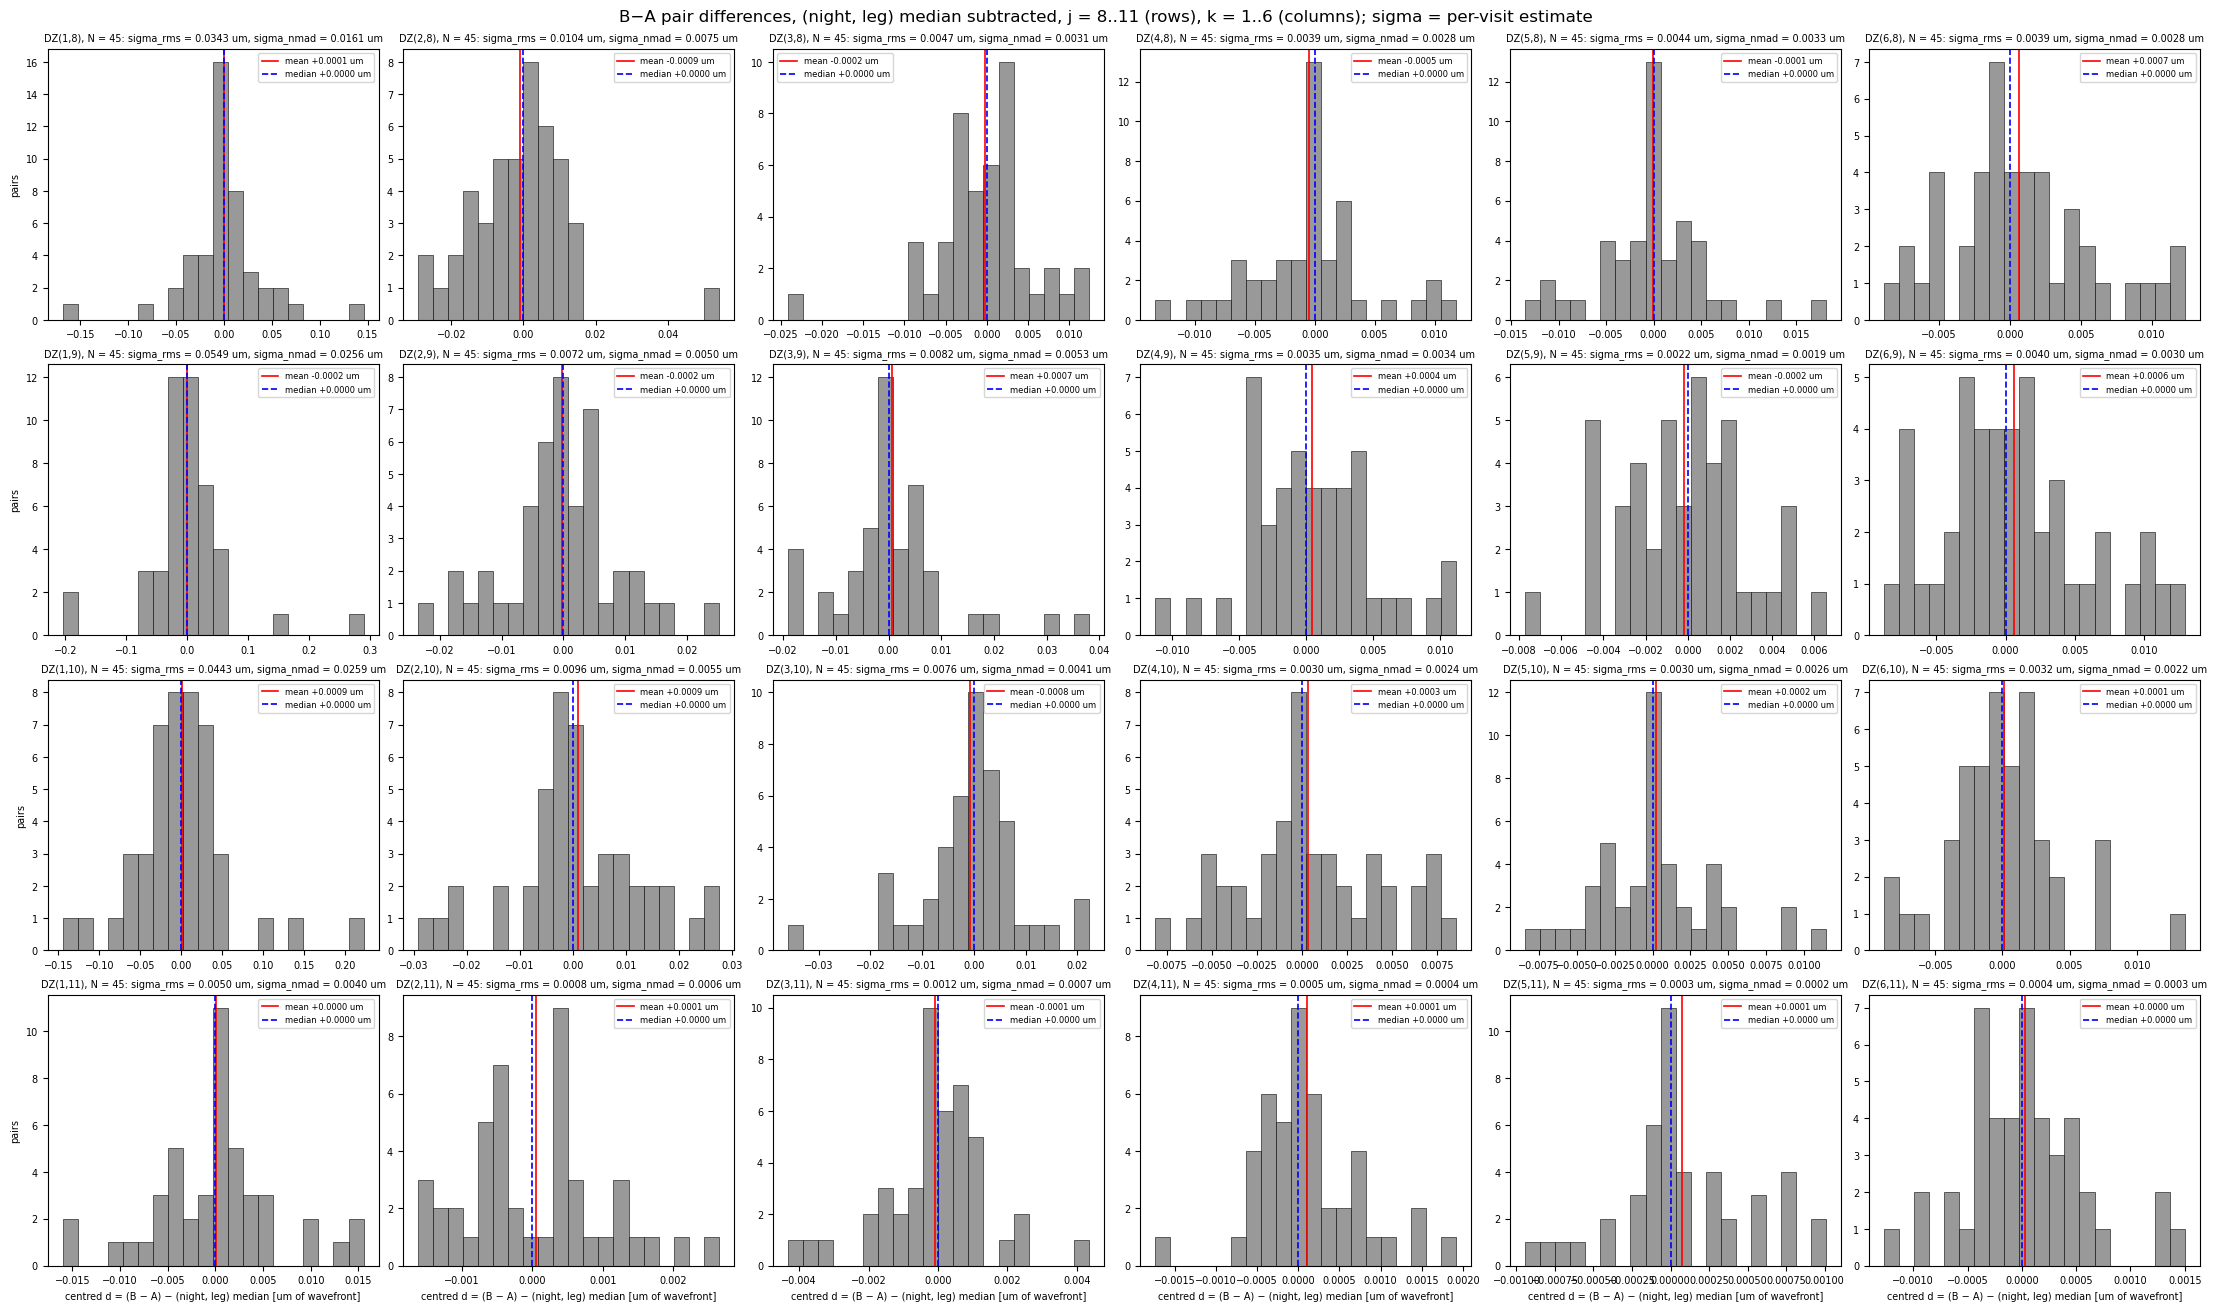

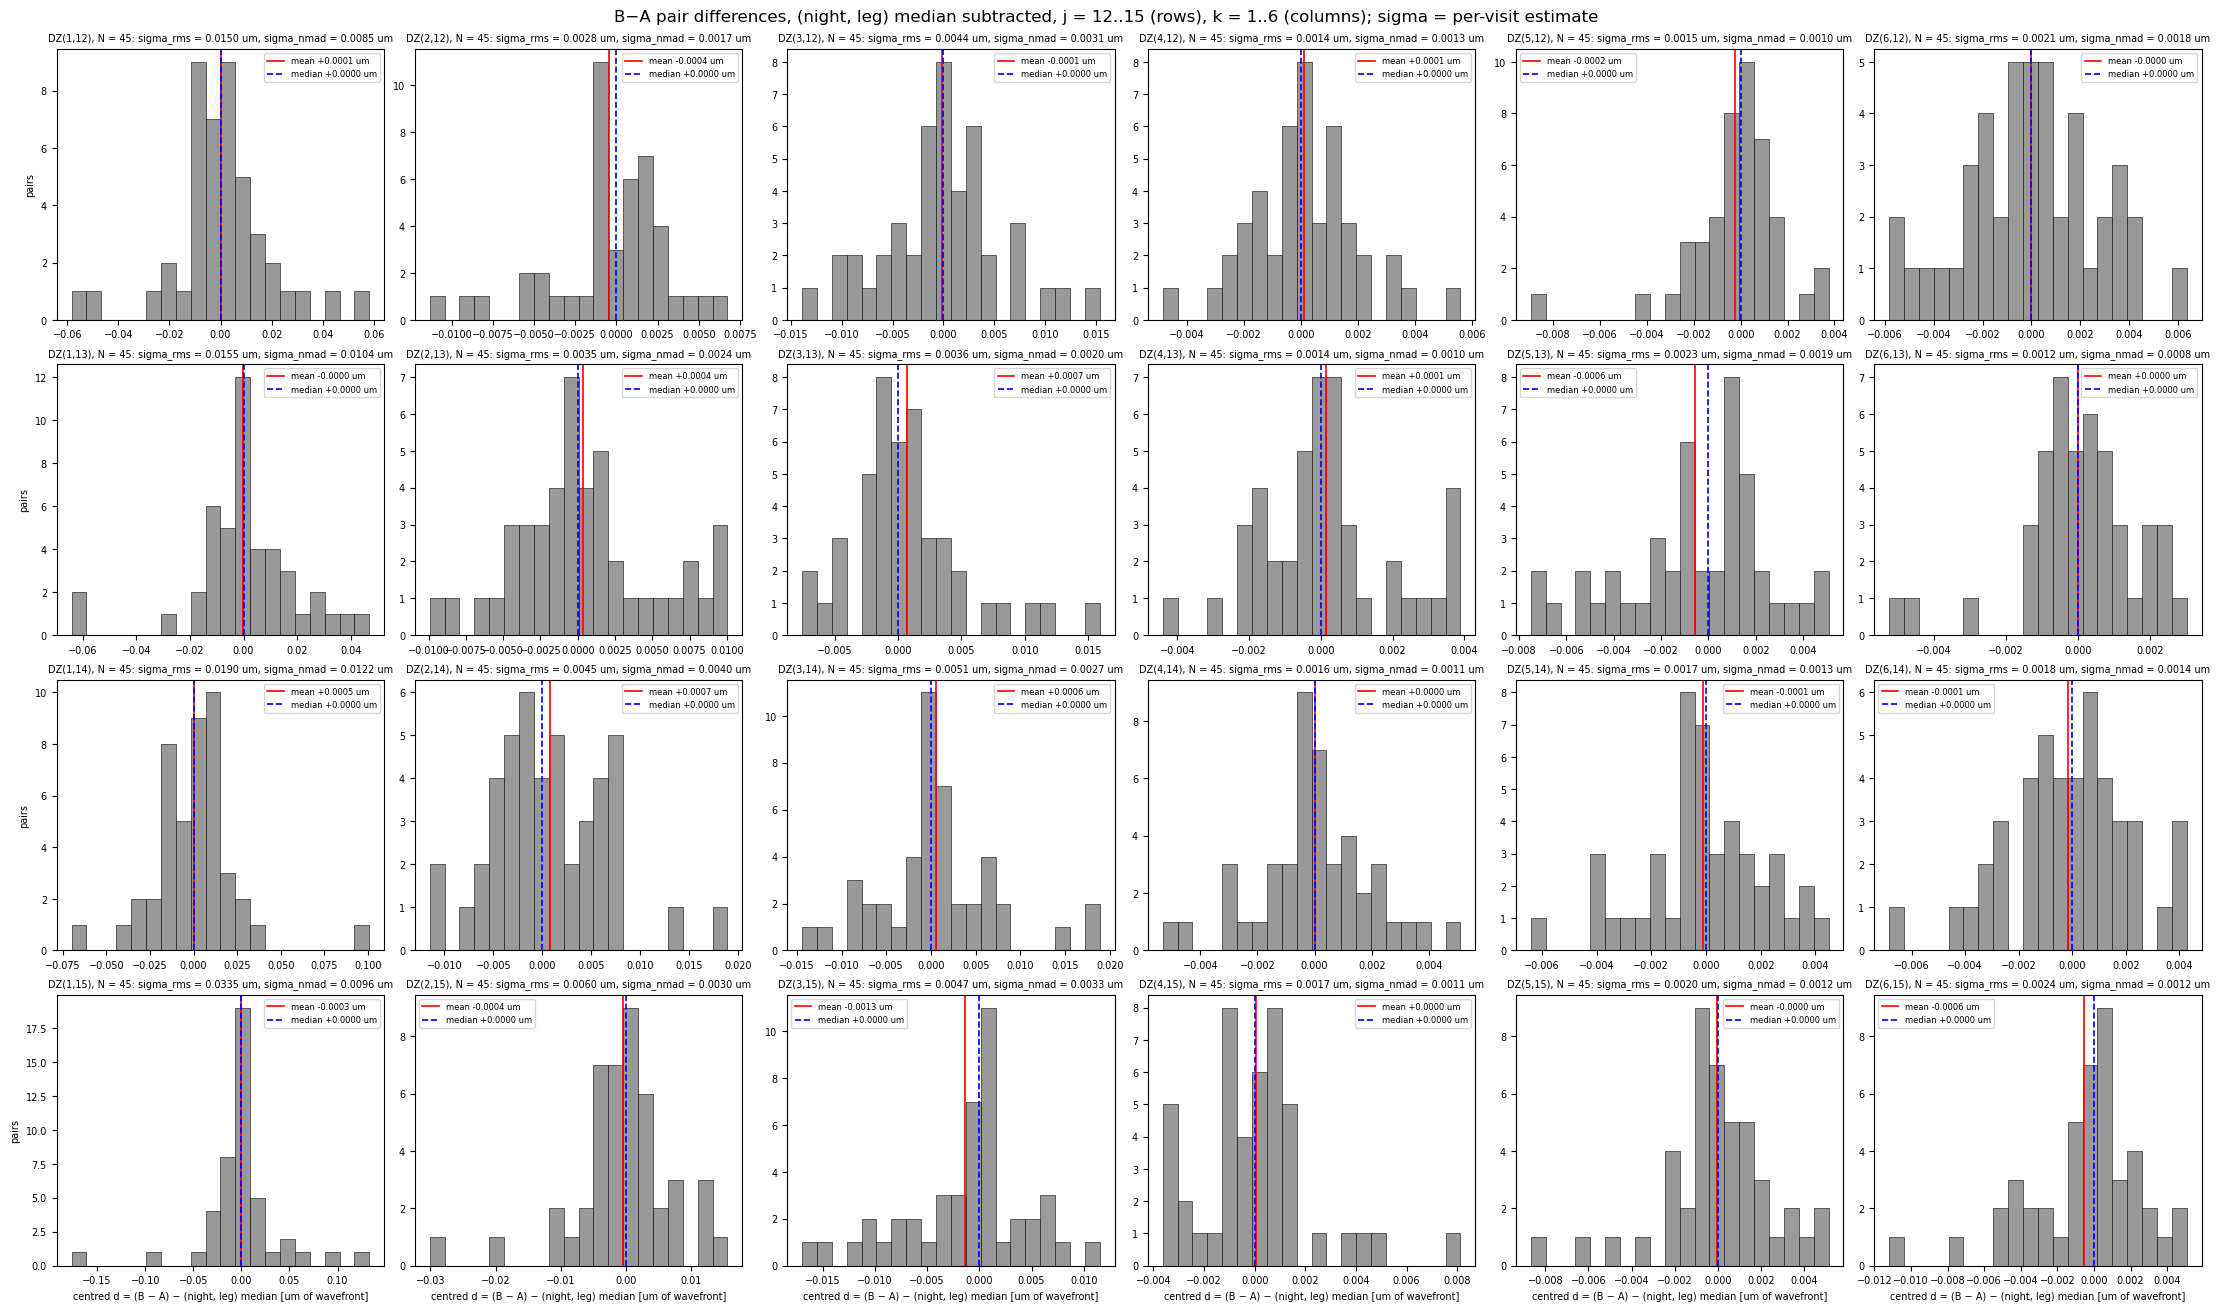

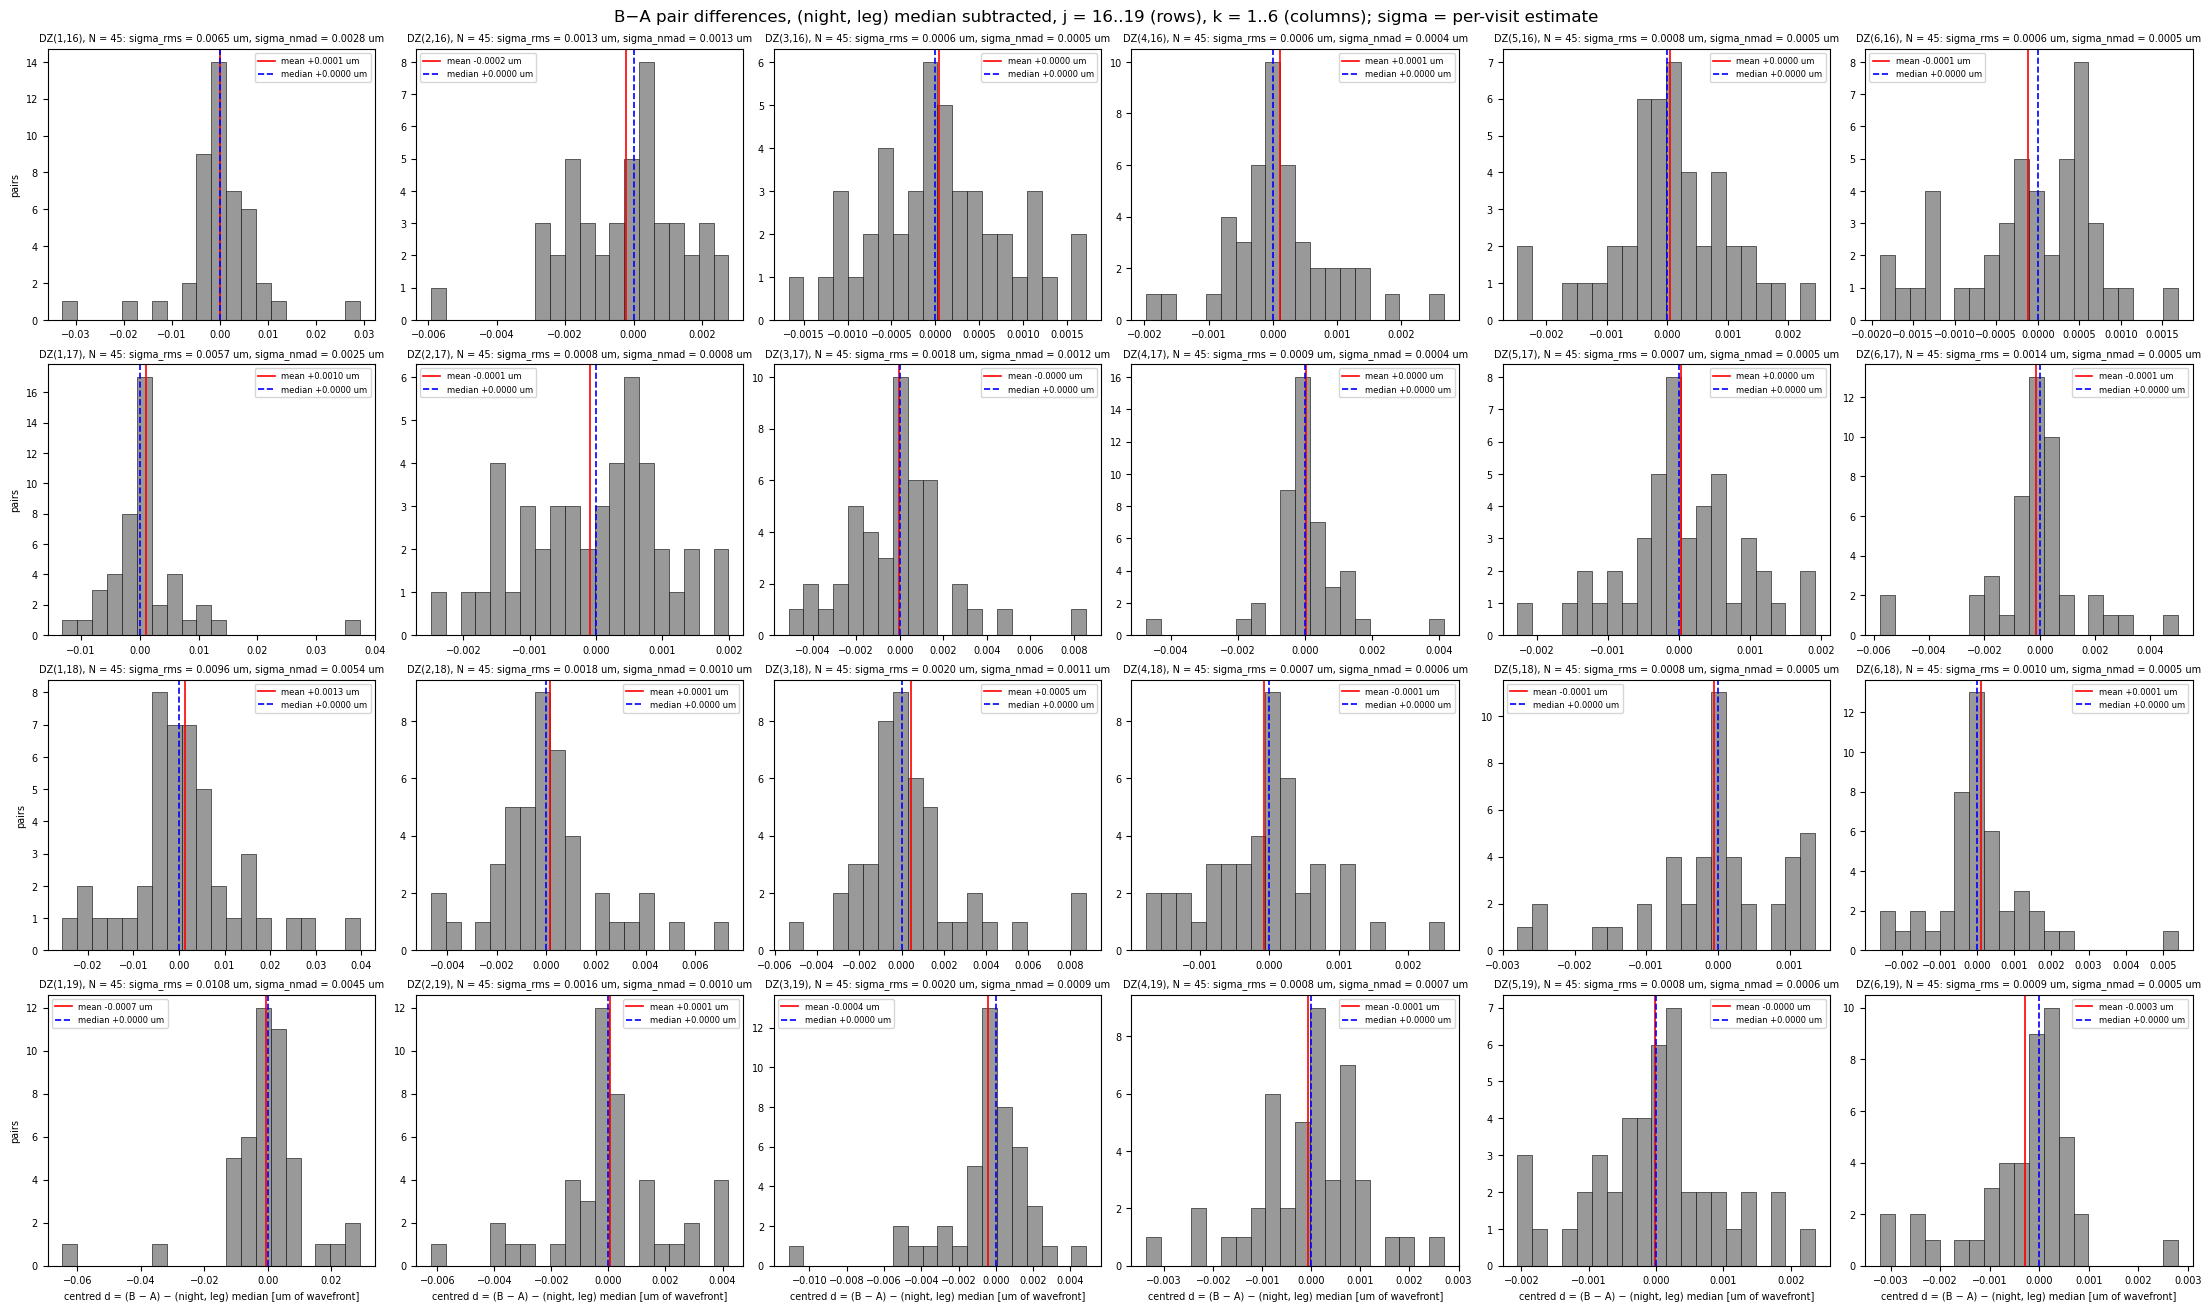

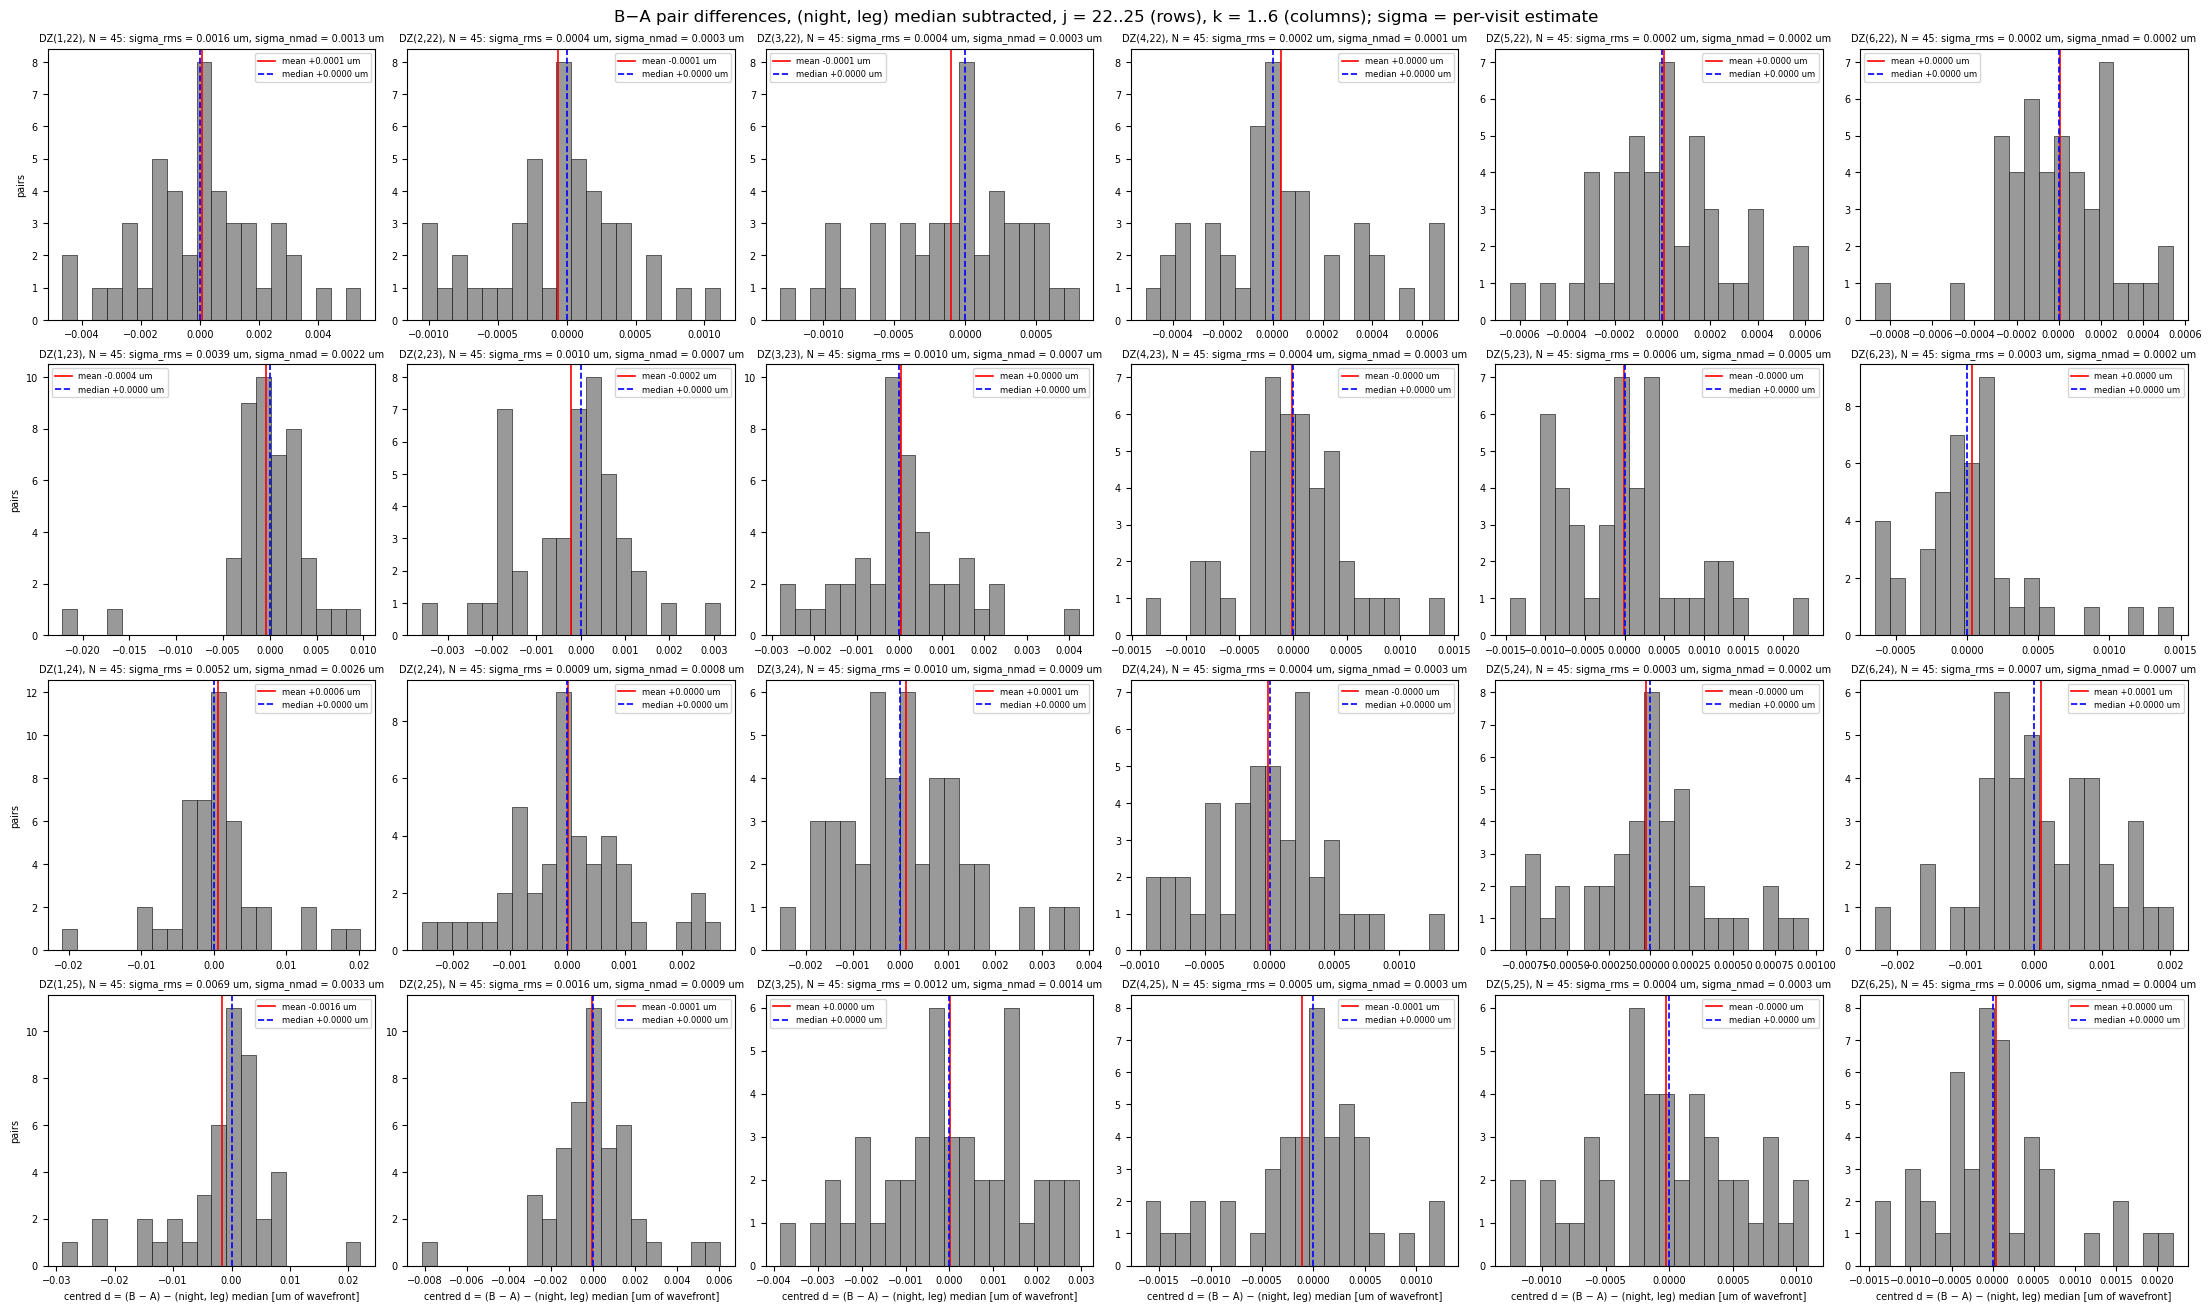

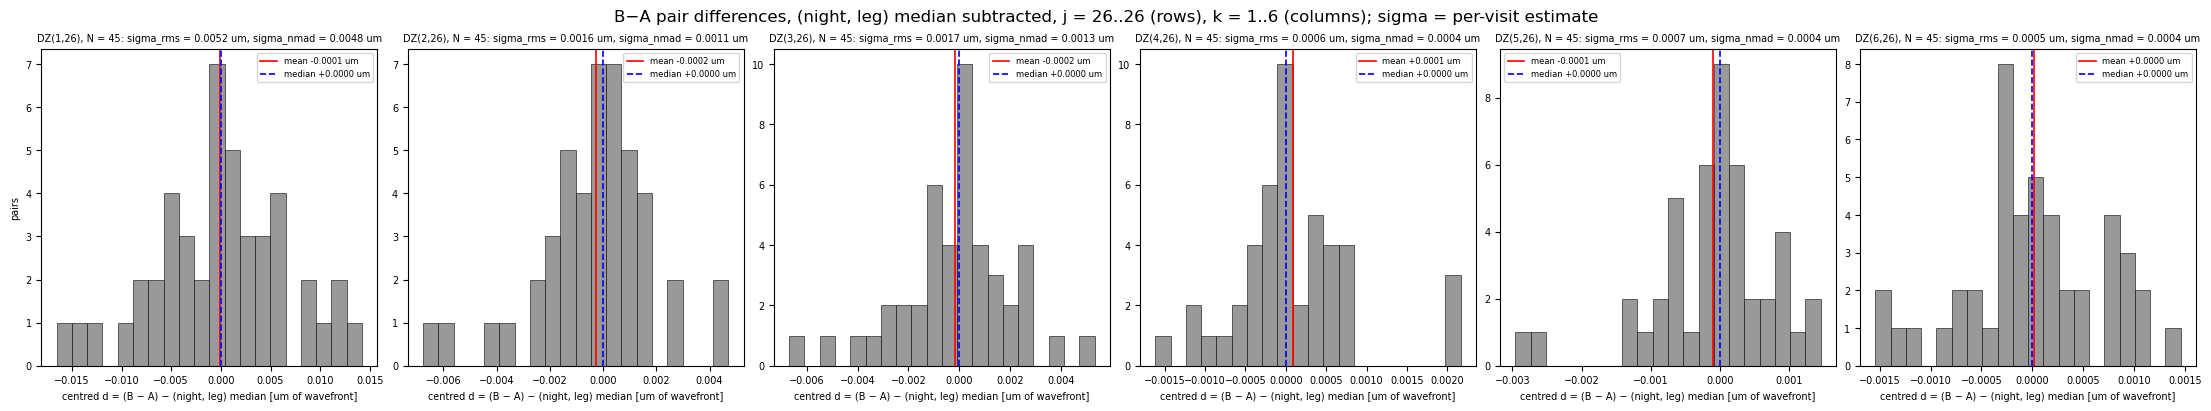

In [6]:
figs_h = []
for p0 in range(0, len(iZs), J_PER_PAGE):
    js = iZs[p0:p0 + J_PER_PAGE]
    fig, axs = plt.subplots(len(js), len(ks), figsize=(22, 3.0 * len(js) + 1.0), layout='constrained',
                            squeeze=False)
    for ri, j in enumerate(js):
        for ci, k in enumerate(ks):
            ix = KJ.index((k, j)); a_ = axs[ri, ci]; x = dc[:, ix]
            a_.hist(x, bins=N_BINS, color='0.6', ec='k', lw=0.4)
            a_.axvline(x.mean(), color='r', lw=1.2, label=f'mean {x.mean():+.4f} um')
            a_.axvline(np.median(x), color='b', lw=1.2, ls='--', label=f'median {np.median(x):+.4f} um')
            a_.set_title(f'DZ({k},{j}), N = {len(x)}: sigma_rms = {rms_w[ix]:.4f} um, '
                         f'sigma_nmad = {nmad_w[ix]:.4f} um', fontsize=7)
            a_.legend(fontsize=6); a_.tick_params(labelsize=7)
            if ri == len(js) - 1:
                a_.set_xlabel('centred d = (B − A) − (night, leg) median [um of wavefront]', fontsize=7)
            if ci == 0:
                a_.set_ylabel('pairs', fontsize=7)
    fig.suptitle(f'B−A pair differences, (night, leg) median subtracted, j = {js[0]}..{js[-1]} (rows), '
                 f'k = 1..6 (columns); sigma = per-visit estimate')
    figs_h.append(fig); plt.show()

<a id='summary'></a>
## Summary

Per-visit white-noise estimate for every DZ_kj, RMS (with its chi2 error) and
nMAD. The dashed line is the expected 0.040 µm Z4 floor.

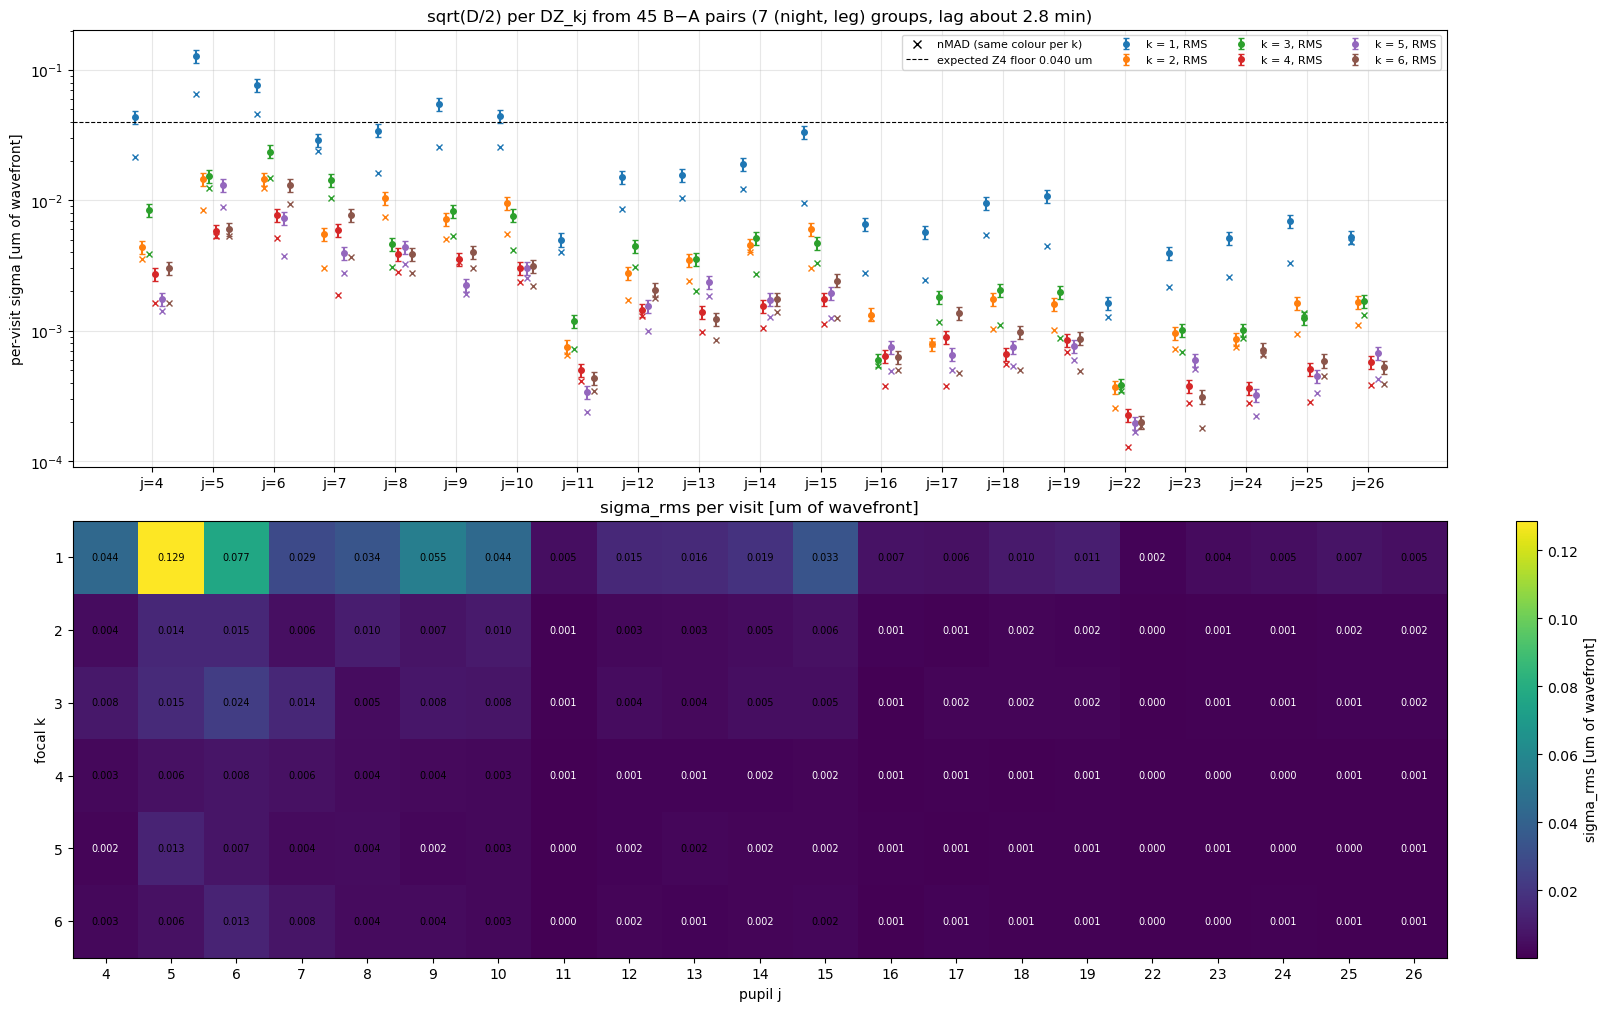

In [7]:
fig_s, axs = plt.subplots(2, 1, figsize=(16, 10), layout='constrained')
jpos = {j: i for i, j in enumerate(iZs)}
for ci, k in enumerate(ks):
    m = tab.k == k; xx = tab[m].j.map(jpos).to_numpy() + (ci - 2.5) * 0.11
    col = plt.get_cmap('tab10')(ci)
    axs[0].errorbar(xx, tab[m].sigma_rms_um, yerr=tab[m].sigma_rms_err_um, fmt='o', ms=4, color=col,
                    capsize=2, label=f'k = {k}, RMS')
    axs[0].plot(xx, tab[m].sigma_nmad_um, 'x', ms=5, color=col)
axs[0].plot([], [], 'kx', label='nMAD (same colour per k)')
axs[0].axhline(FLOOR_Z4_UM, color='k', ls='--', lw=0.8, label=f'expected Z4 floor {FLOOR_Z4_UM:.3f} um')
axs[0].set_xticks(range(len(iZs))); axs[0].set_xticklabels([f'j={j}' for j in iZs])
axs[0].set_ylabel('per-visit sigma [um of wavefront]'); axs[0].set_yscale('log')
axs[0].legend(fontsize=8, ncol=4); axs[0].grid(alpha=0.3)
axs[0].set_title(f'sqrt(D/2) per DZ_kj from {N} B−A pairs ({G} (night, leg) groups, lag about 2.8 min)')
H = np.full((len(ks), len(iZs)), np.nan)
for r in tab.itertuples():
    H[ks.index(r.k), jpos[r.j]] = r.sigma_rms_um
im = axs[1].imshow(H, aspect='auto', cmap='viridis')
for (a, c), v in np.ndenumerate(H):
    axs[1].text(c, a, f'{v:.3f}', ha='center', va='center', fontsize=7, color='w' if v < np.nanmedian(H) else 'k')
axs[1].set_xticks(range(len(iZs))); axs[1].set_xticklabels(iZs)
axs[1].set_yticks(range(len(ks))); axs[1].set_yticklabels(ks)
axs[1].set_xlabel('pupil j'); axs[1].set_ylabel('focal k')
axs[1].set_title('sigma_rms per visit [um of wavefront]')
fig_s.colorbar(im, ax=axs[1], label='sigma_rms [um of wavefront]')
plt.show()

<a id='save'></a>
## Save

In [8]:
if SAVE:
    out = run.path / 'bounce_white_noise_pairs.pdf'
    with PdfPages(str(out)) as pdf:
        pdf.savefig(fig_s)
        for f in figs_h:
            pdf.savefig(f)
    tab.to_csv(run.path / 'bounce_white_noise_pairs.csv', index=False)
    print(out)

/sdf/group/rubin/u/roodman/LSST/rubin-work/studies/aos/bounce/20261102_white_noise_pairs/bounce_white_noise_pairs.pdf
